# Task 69: Custom Prediction Caching & Concurrency Optimization

Implement a thread-safe LRU caching engine from scratch with vector fingerprinting, evaluate smooth state updates, and benchmark multi-threaded concurrent request scaling.


=== SINGLE-INSTANCE INFERENCE LATENCY ===
Cold Start (Cache Miss) Latency : 135.59 µs
Warm Cache (Cache Hit) Latency  : 31.61 µs
In-Memory Caching Speedup      : 4.3x Faster

=== CONCURRENT MULTI-THREADED STRESS TESTING ===
Workers:  1 | Throughput:  23550.4 req/s | Hit Rate:  96.2% | p50: 15.36µs | p99:  65.76µs
Workers:  5 | Throughput:  22835.5 req/s | Hit Rate:  96.2% | p50: 15.06µs | p99:  97.65µs
Workers: 10 | Throughput:  23390.0 req/s | Hit Rate:  96.2% | p50: 15.06µs | p99: 115.44µs
Workers: 25 | Throughput:  15785.3 req/s | Hit Rate:  96.2% | p50: 15.19µs | p99: 126.55µs
Workers: 50 | Throughput:   6802.8 req/s | Hit Rate:  96.2% | p50: 38.56µs | p99: 127.58µs

=== CONCURRENCY BENCHMARK SUMMARY TABLE ===
 Workers  Total_Requests  Total_Time_s  Throughput_RPS  Hit_Rate_Pct  p50_us   p95_us    p99_us  Cache_Size
       1            1500      0.063693    23550.427612          96.2 15.3570 41.54895  65.76276          57
       5            1500      0.065687    22835.450832      

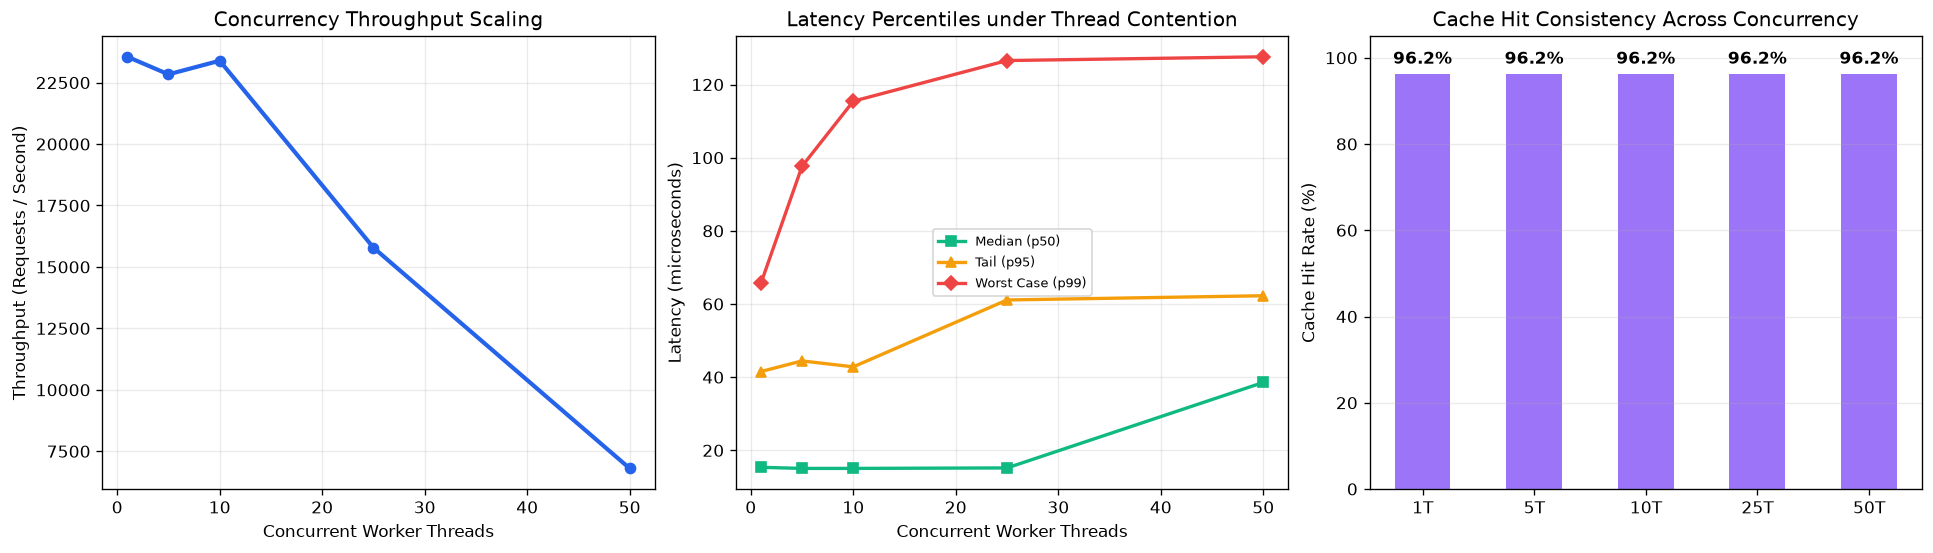

In [1]:
import concurrent.futures
from collections import OrderedDict
from pathlib import Path
import threading
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_69_Custom_Prediction_Caching_Concurrency/heart.csv"), Path("Heart_Disease_Tasks/Task_69_Custom_Prediction_Caching_Concurrency/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)

# Stratified Split & Model
def stratified_split(X, y, test_size=0.2, seed=69):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        cut = int(round(len(idx) * (1 - test_size)))
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=69)
mu = X_train.mean(axis=0)
sd = np.where(X_train.std(axis=0) == 0, 1.0, X_train.std(axis=0))
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

class ScratchLogistic:
    def fit(self, X, y, lr=0.06, iters=1400, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict_proba(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model = ScratchLogistic().fit(X_train_s, y_train)

# Custom Thread-Safe LRU Cache
class ThreadSafeLRUCache:
    def __init__(self, capacity=256):
        self.capacity = capacity
        self.cache = OrderedDict()
        self.lock = threading.RLock()
        self.hits = 0
        self.misses = 0
        self.evictions = 0

    @staticmethod
    def hash_vector(vector, precision=1):
        rounded = tuple(round(float(v), precision) for v in np.asarray(vector).ravel())
        return hash(rounded)

    def get(self, key):
        with self.lock:
            if key in self.cache:
                self.hits += 1
                self.cache.move_to_end(key)
                return self.cache[key]
            self.misses += 1
            return None

    def put(self, key, value):
        with self.lock:
            if key in self.cache:
                self.cache.move_to_end(key)
            self.cache[key] = value
            if len(self.cache) > self.capacity:
                self.cache.popitem(last=False)
                self.evictions += 1

    def stats(self):
        with self.lock:
            total = self.hits + self.misses
            hit_rate = self.hits / total if total > 0 else 0.0
            return {
                "size": len(self.cache),
                "capacity": self.capacity,
                "hits": self.hits,
                "misses": self.misses,
                "hit_rate": hit_rate,
                "evictions": self.evictions
            }

    def clear(self):
        with self.lock:
            self.cache.clear()
            self.hits = 0
            self.misses = 0
            self.evictions = 0

cache = ThreadSafeLRUCache(capacity=256)

def run_inference(raw_vec):
    t0 = time.perf_counter_ns()
    key = cache.hash_vector(raw_vec)
    cached = cache.get(key)
    if cached is not None:
        dt_us = (time.perf_counter_ns() - t0) / 1000.0
        return cached["prob"], cached["pred"], True, dt_us

    std_vec = (raw_vec - mu) / sd
    p = float(model.predict_proba(std_vec[None, :])[0])
    pred = int(p >= 0.5)
    cache.put(key, {"prob": p, "pred": pred})
    dt_us = (time.perf_counter_ns() - t0) / 1000.0
    return p, pred, False, dt_us

# Single-Threaded Benchmark: Hit vs Miss Latency
sample_patient = X_test[0]
_, _, is_hit_1, lat_miss = run_inference(sample_patient)
_, _, is_hit_2, lat_hit = run_inference(sample_patient)

print("=== SINGLE-INSTANCE INFERENCE LATENCY ===")
print(f"Cold Start (Cache Miss) Latency : {lat_miss:.2f} µs")
print(f"Warm Cache (Cache Hit) Latency  : {lat_hit:.2f} µs")
print(f"In-Memory Caching Speedup      : {lat_miss / max(lat_hit, 0.001):.1f}x Faster")

# Concurrent Multi-Threaded Stress Test
print("\n=== CONCURRENT MULTI-THREADED STRESS TESTING ===")
thread_pools = [1, 5, 10, 25, 50]
n_requests = 1500
pool_size = 60

rng = np.random.default_rng(42)
candidate_profiles = [X[rng.integers(0, len(X))] for _ in range(pool_size)]
weights = 1.0 / (np.arange(1, pool_size + 1) ** 0.8)
weights /= weights.sum()
query_indices = rng.choice(pool_size, size=n_requests, p=weights)
queries = [candidate_profiles[idx] for idx in query_indices]

concurrency_results = []
latency_data_by_threads = []

for workers in thread_pools:
    cache.clear()
    latencies = []
    hits = 0
    t0 = time.perf_counter()

    def worker(q):
        p, c_res, hit, lat = run_inference(q)
        return hit, lat

    with concurrent.futures.ThreadPoolExecutor(max_workers=workers) as executor:
        futures = [executor.submit(worker, q) for q in queries]
        for fut in concurrent.futures.as_completed(futures):
            hit, lat = fut.result()
            latencies.append(lat)
            if hit:
                hits += 1

    total_time_sec = time.perf_counter() - t0
    throughput = n_requests / max(total_time_sec, 1e-6)
    hit_rate = (hits / n_requests) * 100.0
    p50 = float(np.percentile(latencies, 50))
    p95 = float(np.percentile(latencies, 95))
    p99 = float(np.percentile(latencies, 99))

    concurrency_results.append({
        "Workers": workers,
        "Total_Requests": n_requests,
        "Total_Time_s": total_time_sec,
        "Throughput_RPS": throughput,
        "Hit_Rate_Pct": hit_rate,
        "p50_us": p50,
        "p95_us": p95,
        "p99_us": p99,
        "Cache_Size": cache.stats()["size"]
    })
    latency_data_by_threads.append(latencies)
    print(f"Workers: {workers:2d} | Throughput: {throughput:8.1f} req/s | Hit Rate: {hit_rate:5.1f}% | p50: {p50:5.2f}µs | p99: {p99:6.2f}µs")

df_concurrency = pd.DataFrame(concurrency_results)
print("\n=== CONCURRENCY BENCHMARK SUMMARY TABLE ===")
print(df_concurrency.to_string(index=False))

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

# 1. Throughput Scaling Curve
axes[0].plot(df_concurrency["Workers"], df_concurrency["Throughput_RPS"], marker="o", color="#2563eb", linewidth=2.5)
axes[0].set_xlabel("Concurrent Worker Threads")
axes[0].set_ylabel("Throughput (Requests / Second)")
axes[0].set_title("Concurrency Throughput Scaling")
axes[0].grid(alpha=0.25)

# 2. Latency Percentiles (p50, p95, p99)
axes[1].plot(df_concurrency["Workers"], df_concurrency["p50_us"], marker="s", color="#10b981", linewidth=2, label="Median (p50)")
axes[1].plot(df_concurrency["Workers"], df_concurrency["p95_us"], marker="^", color="#f59e0b", linewidth=2, label="Tail (p95)")
axes[1].plot(df_concurrency["Workers"], df_concurrency["p99_us"], marker="D", color="#ef4444", linewidth=2, label="Worst Case (p99)")
axes[1].set_xlabel("Concurrent Worker Threads")
axes[1].set_ylabel("Latency (microseconds)")
axes[1].set_title("Latency Percentiles under Thread Contention")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)

# 3. Cache Hit Ratio & Size Progression
axes[2].bar([f"{w}T" for w in df_concurrency["Workers"]], df_concurrency["Hit_Rate_Pct"], color="#8b5cf6", width=0.5, alpha=0.85)
for i, h in enumerate(df_concurrency["Hit_Rate_Pct"]):
    axes[2].text(i, h + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontweight="bold")
axes[2].set_ylabel("Cache Hit Rate (%)")
axes[2].set_ylim(0, 105)
axes[2].set_title("Cache Hit Consistency Across Concurrency")
axes[2].grid(axis="y", alpha=0.25)

plt.show()
